In [ ]:
# imports
import numpy as np
#feature extraction from the image
## importing the necessary modules for feature extraction 
import torch
import torch.nn as nn
from torchvision import transforms, datasets
from torch.utils.data import Dataset, DataLoader
data = {}

#data['test']  = np.load('drive/MyDrive/dataverse_files/Dataset5_raw_test.npz')
#data['train'] = dict(np.load('dataverse_files/Dataset5_raw_train.npz'))
#data['val']   = dict(np.load('dataverse_files/Dataset5_raw_val.npz'))

In [ ]:


# normalize image data
# N x 224 x 224 x3 
# take avg of N images 

mean = data['train']['image'].mean(axis=(0,1,2), keepdims=True)
devia = data['train']['image'].std(axis=(0,1,2), keepdims=True)
data['train']['image'] = (data['train']['image'] - mean) / devia
data['val']['image'] = (data['val']['image'] - mean) / devia

In [ ]:
class CustomDataset(Dataset):
    def __init__(self, data, labels, transform):
        self.transform = transform
        self.data = data
        self.labels = labels
    
    def __len__(self):
        return self.labels.size

    def __getitem__(self, idx):
        temp = int(self.labels[idx])
            
        return self.transform(self.data[idx]).float(), temp

In [ ]:
transform = transforms.Compose([transforms.ToTensor()])
print(data['train']['image'].transpose(0, 3, 1, 2).shape)
trainset = CustomDataset(data['train']['image'], data['train']['image_label'], transform)
train_loader = DataLoader(trainset, 64, shuffle=True, drop_last=True)

(19610, 3, 224, 224)


In [ ]:
class Model(nn.Module):
  def __init__(self, cnn):
    super().__init__()
    self.cnn = cnn

    self.fcn = nn.Sequential(
            nn.Linear(1000, 5),
            nn.Softmax(),
        )

  def forward(self, inp):
    return self.cnn(inp)

  def save_FExt(self):
    torch.save(self.cnn.state_dict(), 'vgg16_xray')

  def load_FExt(self):
    model.load_state_dict(torch.load("feweights/modelres18_57.pth"))

In [ ]:
import torchvision

resnet18 = torchvision.models.resnet18()
model = Model(resnet18)
model.load_FExt()
model.eval()

Model(
  (cnn): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_s

In [ ]:
y_pred = []
y_train = []
for x, y in train_loader:
    y_pred = y_pred + model(x).detach().numpy().tolist()
    y_train = y_train + y.detach().numpy().tolist()
    
print(len(y_pred))
print(len(y_train))

19584
19584


In [ ]:
print(data['val']['image'].transpose(0, 3, 1, 2).shape)

valset = CustomDataset(data['val']['image'], data['val']['image_label'], transform)
val_loader = DataLoader(valset, 1, shuffle=True)

(6534, 3, 224, 224)


In [ ]:
y_pred_val = []
y_val = []
for x, y in val_loader:
    y_pred_val.append(model(x).detach().numpy())
    y_val.append(y.detach().numpy()[0])
    
print(len(y_pred_val))
print(y_pred_val[1].shape)
print(len(y_val))

6534
(1, 1000)
6534


In [ ]:
def relu(Z):
    return Z*(Z>0)

def relu_backward(Z):
    return 1* (Z>0)

def softmax(Z):
    return np.exp(Z) / np.sum(np.exp(Z), axis = 1, keepdims=True)

class FCN():
    def __init__(self, dims, activation, lr, momentum, initialization, weight_decay, uniform_decay):
      '''
      uniform_decay -> for 
      '''      
        self.dims = dims
        self.activation = activation
        self.lr = lr
        self.momentum = momentum
        self.unif_decay = uniform_decay
        self.weight_decay = weight_decay

        self.weights  = {}
        self.bias = {}
        self.deltaW = {}
        self.v = {}

        for i in range(len(dims)-1):
            self.deltaW['L'+str(i+1)] = 0
            self.deltaW['b'+str(i+1)] = 0
            self.v['L'+str(i+1)] = 0
            self.v['b'+str(i+1)] = 0

            self.weights['L'+str(i+1)] = np.random.normal(0, 0.0001, (dims[i+1], dims[i]))
            self.bias['L'+str(i+1)]    = np.random.normal(0, 0.0001, (dims[i+1], 1))

        
    def forward_pass(self, input):
        self.out = {}
        self.out['L0'] = input
        self.out['F0'] = input
        L = len(self.dims)-1

        for i in range(L-1):         
            self.out['L'+str(i+1)] = self.out['L'+str(i)] @ self.weights['L'+str(i+1)].T
            self.out['L'+str(i+1)] = self.out['L'+str(i+1)] + self.bias['L'+str(i+1)].T
            self.out['F'+str(i+1)] = relu(self.out['L'+str(i+1)])

        self.out['L'+str(L)] = self.out['L'+str(L-1)] @ self.weights['L'+str(L)].T 
        self.out['L'+str(L)] = self.out['L'+str(L)] + self.bias['L'+str(L)].T
        self.out['F'+str(L)] = softmax(self.out['L'+str(L)])

        
        return self.out['F'+str(L)]

    
    # considering E to be of the form NxO
    def back_pass(self, err):
        L = len(self.dims) - 1
        dW = {}

        dW['L'+str(L)] = err.T  @ self.out['F'+str(L-1)]
        dW['b'+str(L)] = np.sum(err, axis=0, keepdims=True)
        err = ( err @ self.weights['L'+str(L)]) * relu_backward(self.out['L'+str(L-1)])

        if self.momentum != None:
              self.deltaW['L'+str(L)] = (self.momentum * self.deltaW['L'+str(L)]) + ((1 - self.momentum)* dW['L'+str(L)])
              self.deltaW['b'+str(L)] = (self.momentum * self.deltaW['b'+str(L)]) + ((1 - self.momentum)* dW['b'+str(L)])

        if self.unif_decay != None:
              self.v['L'+str(L)] = (self.unif_decay * self.v['L'+str(L)]) + ((1 - self.unif_decay)* dW['L'+str(L)])
              self.v['b'+str(L)] = (self.unif_decay * self.v['b'+str(L)]) + ((1 - self.unif_decay)* dW['b'+str(L)])

        for i in range(L-1):
            dW['L'+str(L-1-i)] = err.T  @ self.out['F'+str(L-2-i)]
            dW['b'+str(L-1-i)] = np.sum(err, axis=0, keepdims=True)
            err = ( err @ self.weights['L'+str(L-1-i)]) * relu_backward(self.out['L'+str(L-2-i)])

            if self.momentum != None:
              self.deltaW['L'+str(L-1-i)] = (self.momentum * self.deltaW['L'+str(L-1-i)]) + ((1 - self.momentum)* dW['L'+str(L-1-i)])
              self.deltaW['b'+str(L-1-i)] = (self.momentum * self.deltaW['b'+str(L-1-i)]) + ((1 - self.momentum)* dW['b'+str(L-1-i)])

    def update_weights(self):
        L = len(self.dims) - 1
        
        for i in range(L):
            if self.weight_decay != None:
              self.weights['L'+str(i+1)] = self.weights['L'+str(i+1)] - (self.lr*self.weight_decay*self.weights['L'+str(i+1)])

            self.weights['L'+str(i+1)] = self.weights['L'+str(i+1)] + self.lr * (self.deltaW['L'+str(i+1)])
            self.bias['L'+str(i+1)] = self.bias['L'+str(i+1)] + self.lr * (self.deltaW['b'+str(i+1)].T)

    def cache_bestweights(self):
        self.best = {}
        self.best['w'] = self.weights
        self.best['b'] = self.bias

In [ ]:
y_true = np.zeros(shape=(len(y_train), 5))
for i in range(len(y_train)):
    y_true[i, y_train[i]] = 1

y_true.shape

(19584, 5)

In [ ]:
y_true_val = np.zeros(shape=(len(y_val), 5))
for i in range(len(y_val)):
    y_true_val[i, y_val[i]] = 1

print(y_true_val.shape)

(6534, 5)


In [ ]:
def cross_entropy_loss(AL, Y):
    m = Y.shape[0]
    cost = -1 * np.sum(np.multiply( np.log(AL), Y) + np.multiply( np.log(1 - AL), 1 - Y)) / m
    cost = np.squeeze(cost)

    return cost

y_net = np.reshape(np.array(y_pred),(-1,1000))
y_net_val = np.array(y_pred_val).reshape(-1,1000)
### normalize the outputs from the feature extractor

mlp   = FCN([1000, 5], None, 0.00000001, 0.9, None, 0)

accuracy = []
val_errors = []
train_errors = []
max = 0
## training loop
batch_size = 1
iterations = int(y_net.shape[0] / batch_size)
val_iter   = y_net_val.shape[0]

for i in range(100):
    print('Epoch:' + str(i+1))
    train_error = 0
    val_error = 0
    val_correct = 0

    # batch size = 16
    for j in range(iterations):
        out = mlp.forward_pass(y_net[j*batch_size: j*batch_size+batch_size,])
        #print(out)
        train_error += cross_entropy_loss(out, y_true[j*batch_size: j*batch_size+batch_size,])
        err = (y_true[j*batch_size:j*batch_size+batch_size] - out) / batch_size
        #print(err)
        
        mlp.back_pass(err)
        mlp.update_weights()

    for j in range(val_iter):
        out = mlp.forward_pass(y_net_val[j:j+1,])
        val_error += cross_entropy_loss(out, y_true_val[j:j+1,])
        # count correct
        correct = np.argmax(out, axis=1)

        if correct[0] == y_val[j]:
            val_correct += 1
    
    val_error = val_error / val_iter
    train_error = train_error / iterations

    train_errors.append(train_error)
    val_errors.append(val_error)
    accuracy.append(100*val_correct/val_iter)
    
    if accuracy[-1] > max:
        max = accuracy[-1]
        mlp.cache_bestweights()

    print('Correct Predictions %(VAL) = ', accuracy[-1])
    print('Error (VAL) = ', val_error)
    print('Error (Train) = ', train_error)

Epoch:1
Correct Predictions %(VAL) =  71.28864401591674
Error (VAL) =  2.4779739261802796
Error (Train) =  2.4893084385735826
Epoch:2
Correct Predictions %(VAL) =  71.41108050198959
Error (VAL) =  2.454866930405858
Error (Train) =  2.4651612040200996
Epoch:3
Correct Predictions %(VAL) =  71.12029384756657
Error (VAL) =  2.4322305240044306
Error (Train) =  2.4414943188733162
Epoch:4
Correct Predictions %(VAL) =  70.73767982858892
Error (VAL) =  2.4100567292032467
Error (Train) =  2.4182998305271837
Epoch:5
Correct Predictions %(VAL) =  70.56932966023875
Error (VAL) =  2.388337670409508
Error (Train) =  2.3955698976894784
Epoch:6
Correct Predictions %(VAL) =  70.32445668809305
Error (VAL) =  2.367065540505385
Error (Train) =  2.3732967556052476
Epoch:7
Correct Predictions %(VAL) =  70.27854300581573
Error (VAL) =  2.3462325721536965
Error (Train) =  2.3514726817420053
Epoch:8
Correct Predictions %(VAL) =  70.27854300581573
Error (VAL) =  2.3258310142218352
Error (Train) =  2.330089967395

In [ ]:
def cross_entropy_loss(AL, Y):
    m = Y.shape[0]
    cost = -1 * np.sum(np.multiply( np.log(AL), Y) + np.multiply( np.log(1 - AL), 1 - Y)) / m
    cost = np.squeeze(cost)

    return cost

y_net = np.reshape(np.array(y_pred),(-1,1000))
y_net_val = np.array(y_pred_val).reshape(-1,1000)
### normalize the outputs from the feature extractor

mlp   = FCN([1000, 100, 5], None, 0.000001, 0.9, None, 0)

accuracy = []
val_errors = []
train_errors = []
max = 0
## training loop
batch_size = 1
iterations = int(y_net.shape[0] / batch_size)
val_iter   = y_net_val.shape[0]

for i in range(100):
    print('Epoch:' + str(i+1))
    train_error = 0
    val_error = 0
    val_correct = 0

    # batch size = 16
    for j in range(iterations):
        out = mlp.forward_pass(y_net[j*batch_size: j*batch_size+batch_size,])
        #print(out)
        train_error += cross_entropy_loss(out, y_true[j*batch_size: j*batch_size+batch_size,])
        err = (y_true[j*batch_size:j*batch_size+batch_size] - out) / batch_size
        #print(err)
        
        mlp.back_pass(err)
        mlp.update_weights()

    for j in range(val_iter):
        out = mlp.forward_pass(y_net_val[j:j+1,])
        val_error += cross_entropy_loss(out, y_true_val[j:j+1,])
        # count correct
        correct = np.argmax(out, axis=1)

        if correct[0] == y_val[j]:
            val_correct += 1
    
    val_error = val_error / val_iter
    train_error = train_error / iterations

    train_errors.append(train_error)
    val_errors.append(val_error)
    accuracy.append(100*val_correct/val_iter)
    
    if accuracy[-1] > max:
        max = accuracy[-1]
        mlp.cache_bestweights()

    print('Correct Predictions %(VAL) = ', accuracy[-1])
    print('Error (VAL) = ', val_error)
    print('Error (Train) = ', train_error)

Epoch:1
Correct Predictions %(VAL) =  31.190694827058465
Error (VAL) =  2.5014993365291183
Error (Train) =  2.501764903141405
Epoch:2
Correct Predictions %(VAL) =  31.190694827058465
Error (VAL) =  2.5009698943513663
Error (Train) =  2.501235633580031
Epoch:3
Correct Predictions %(VAL) =  31.190694827058465
Error (VAL) =  2.5004367689708302
Error (Train) =  2.5007048250898087
Epoch:4
Correct Predictions %(VAL) =  31.190694827058465
Error (VAL) =  2.4998935101033046
Error (Train) =  2.5001670327341117
Epoch:5
Correct Predictions %(VAL) =  31.190694827058465
Error (VAL) =  2.4993298732495877
Error (Train) =  2.4996138791471134
Epoch:6
Correct Predictions %(VAL) =  31.190694827058465
Error (VAL) =  2.4987288832693952
Error (Train) =  2.499031695476665
Epoch:7
Correct Predictions %(VAL) =  31.190694827058465
Error (VAL) =  2.4980620254266563
Error (Train) =  2.498397625874442
Epoch:8
Correct Predictions %(VAL) =  31.190694827058465
Error (VAL) =  2.497281221295478
Error (Train) =  2.497673

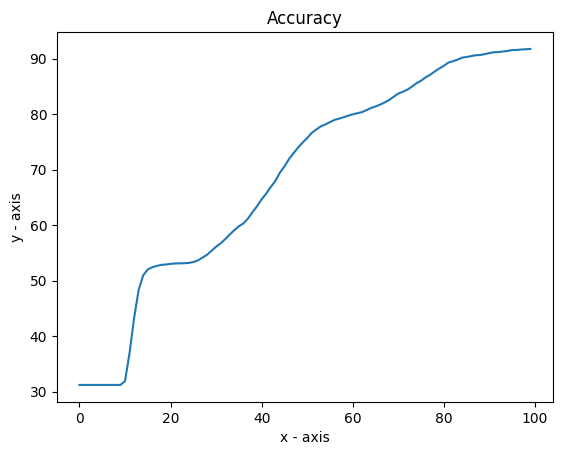

In [ ]:
import matplotlib.pyplot as plt

# x axis values 
x = range(100)
# corresponding y axis values 
y = accuracy
    
# plotting the points  
plt.plot(x, y) 
    
# naming the x axis 
plt.xlabel('x - axis') 
# naming the y axis 
plt.ylabel('y - axis') 
    
# giving a title to my graph 
plt.title('Accuracy') 
    
# function to show the plot 
plt.show() 


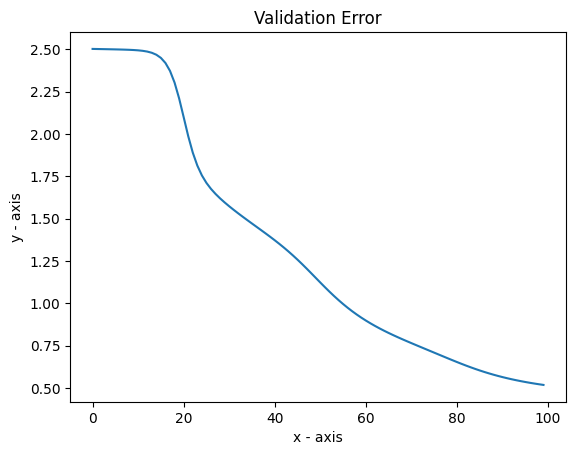

In [ ]:
# x axis values 
x = range(100)
# corresponding y axis values 
y = val_errors
    
# plotting the points  
plt.plot(x, y) 
    
# naming the x axis 
plt.xlabel('x - axis') 
# naming the y axis 
plt.ylabel('y - axis') 
    
# giving a title to my graph 
plt.title('Validation Error') 
    
# function to show the plot 
plt.show() 

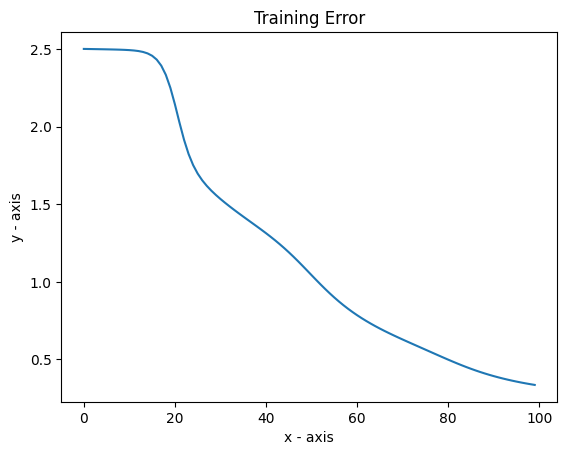

In [ ]:
# x axis values 
x = range(100)
# corresponding y axis values 
y = train_errors
    
# plotting the points  
plt.plot(x, y) 
    
# naming the x axis 
plt.xlabel('x - axis') 
# naming the y axis 
plt.ylabel('y - axis') 
    
# giving a title to my graph 
plt.title('Training Error') 
    
# function to show the plot 
plt.show()

In [ ]:
import pickle

with open('best_weights.pkl', 'wb') as fp:
    pickle.dump(mlp.best, fp)
    print('dictionary saved successfully to file')

dictionary saved successfully to file


In [ ]:
import pickle

with open('best_weights_w.pkl', 'wb') as fp:
    pickle.dump(mlp.weights, fp)
    print('dictionary saved successfully to file')

with open('best_weights_bias.pkl', 'wb') as fp:
    pickle.dump(mlp.bias, fp)
    print('dictionary saved successfully to file')

dictionary saved successfully to file
dictionary saved successfully to file


In [ ]:
import pickle

with open('best_weights_w.pkl', 'wb') as fp:
    pickle.dump(mlp.weights, fp)
    print('dictionary saved successfully to file')

with open('best_weights_bias.pkl', 'wb') as fp:
    pickle.dump(mlp.bias, fp)
    print('dictionary saved successfully to file')

In [ ]:
import pickle
import numpy as np
import torch
import torch.nn as nn
from torchvision import transforms, datasets
from torch.utils.data import Dataset, DataLoader

data = {}
data['train']  = dict(np.load('dataverse_files/Dataset5_raw_train.npz'))
data['test']  = dict(np.load('dataverse_files/Dataset5_raw_test.npz'))

mean = data['train']['image'].mean(axis=(0,1,2), keepdims=True)
devia = data['train']['image'].std(axis=(0,1,2), keepdims=True)
data['test']['image'] = (data['test']['image'] - mean) / devia

transform = transforms.Compose([transforms.ToTensor()])
print(data['test']['image'].transpose(0, 3, 1, 2).shape)
testset = CustomDataset(data['test']['image'], data['test']['image_label'], transform)
test_loader = DataLoader(testset, 1, shuffle=True)

with open('best_weights_w.pkl', 'rb') as fp:
    weights = pickle.load(fp)
    print('dictionary saved successfully to file')

with open('best_weights_bias.pkl', 'rb') as fp:
    bias = pickle.load(fp)
    print('dictionary saved successfully to file')

y_pred = []
y_train = []
for x, y in test_loader:
    y_pred = y_pred + model(x).detach().numpy().tolist()
    y_train = y_train + y.detach().numpy().tolist()
    
print(len(y_pred))
print(len(y_train))

y_true = np.zeros(shape=(len(y_train), 5))
for i in range(len(y_train)):
    y_true[i, y_train[i]] = 1

def cross_entropy_loss(AL, Y):
    m = Y.shape[0]
    cost = -1 * np.sum(np.multiply( np.log(AL), Y) + np.multiply( np.log(1 - AL), 1 - Y)) / m
    cost = np.squeeze(cost)

    return cost

y_net = np.reshape(np.array(y_pred),(-1,1000))
mlp   = FCN([1000, 100, 5], None, 0.000001, 0.9, None, 0)
mlp.weights = weights
mlp.bias    = bias

test_error = 0
correct_count = 0

for j in range(len(y_train)):
    out = mlp.forward_pass(y_net[j:j+1,])
    test_error += cross_entropy_loss(out, y_true[j:j+1,])
    # count correct
    correct = np.argmax(out, axis=1)

    if correct[0] == y_train[j]:
        correct_count += 1

test_error = test_error / len(y_train)

print('Correct Predictions %(TEST) = ', 100*correct_count/len(y_train))
print('Error (Train) = ', test_error)

(6540, 3, 224, 224)
dictionary saved successfully to file
dictionary saved successfully to file
6540
6540
Correct Predictions %(TEST) =  91.23853211009174
Error (Train) =  0.544204465408201
